In [1]:
%pip install tensorflow==2.15.0 numpy==1.26.4 pandas matplotlib h5py

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement tensorflow==2.15.0 (from versions: 2.16.0rc0, 2.16.1, 2.16.2, 2.17.0rc0, 2.17.0rc1, 2.17.0, 2.17.1, 2.18.0rc0, 2.18.0rc1, 2.18.0rc2, 2.18.0, 2.18.1, 2.19.0rc0, 2.19.0, 2.19.1, 2.20.0rc0, 2.20.0, 2.21.0rc0, 2.21.0rc1, 2.21.0, 2.22.0rc0)
ERROR: No matching distribution found for tensorflow==2.15.0


E:\anaconda\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
83/83 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0301 - val_loss: 0.0203
Epoch 2/5
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0195 - val_loss: 0.0188
Epoch 3/5
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0187 - val_loss: 0.0175
Epoch 4/5
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0167 - val_loss: 0.0157
Epoch 5/5
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0158 - val_loss: 0.0165
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Threshold: 0.039073126684799675
Anomalies Detected: 1813


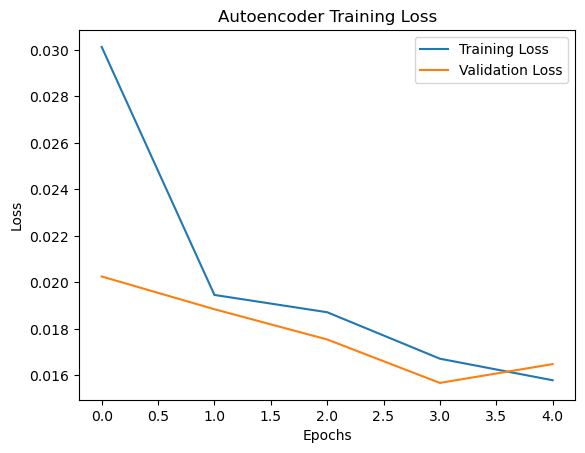

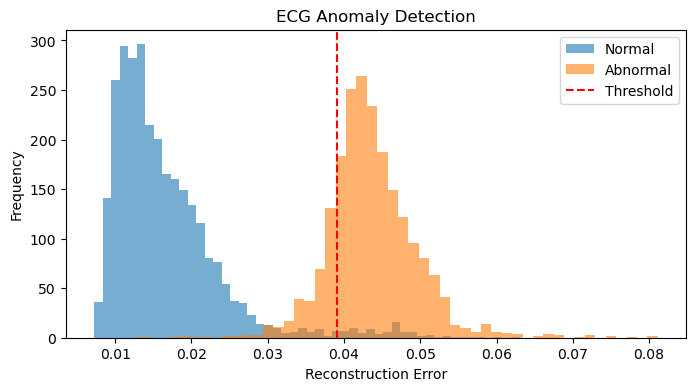

In [1]:
%matplotlib inline

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load ECG dataset
url = "http://storage.googleapis.com/download.tensorflow.org/data/ecg.csv"
data = pd.read_csv(url, header=None)

# Separate features and labels
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

# Normalize data
X = (X - X.min()) / (X.max() - X.min())

# Split normal and abnormal data
normal = X[y == 1]
abnormal = X[y == 0]

# Build Autoencoder
model = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(X.shape[1],)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(X.shape[1], activation='sigmoid')
])

# Compile model
model.compile(optimizer='adam', loss='mae')

# Train only on normal ECG signals
history = model.fit(
    normal, normal,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

# Calculate reconstruction errors
reconstructed = model.predict(X)
errors = np.mean(np.abs(X - reconstructed), axis=1)

# Set anomaly threshold
threshold = np.mean(errors[y == 1]) + 3 * np.std(errors[y == 1])

# Detect anomalies
predictions = errors > threshold

print("Threshold:", threshold)
print("Anomalies Detected:", np.sum(predictions))

# Plot training loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Plot reconstruction errors
plt.figure(figsize=(8, 4))
plt.hist(errors[y == 1], bins=50, alpha=0.6, label='Normal')
plt.hist(errors[y == 0], bins=50, alpha=0.6, label='Abnormal')
plt.axvline(threshold, color='red', linestyle='--', label='Threshold')
plt.title('ECG Anomaly Detection')
plt.xlabel('Reconstruction Error')
plt.ylabel('Frequency')
plt.legend()
plt.show()